# Telco Customer Churn Prediction using Machine Learning

## Project Overview

Customer churn occurs when customers stop using a company's services. In the telecommunications industry, predicting customer churn is important because retaining existing customers is often more cost-effective than acquiring new ones.

In this project, we analyse the Telco Customer Churn dataset and build machine learning models to predict whether a customer is likely to churn.

The main objectives of this notebook are to:

• Inspect and clean the dataset  
• Perform feature engineering and preprocessing  
• Scale the dataset for machine learning models  
• Train classification models to predict churn  
• Evaluate model performance using several metrics  
• Identify the most important features influencing churn

## Importing Required Libraries

This section imports the necessary Python libraries used throughout the analysis.

- **pandas** is used for data manipulation and analysis.
- **numpy** is used for numerical operations.
- **matplotlib** and **seaborn** are used for data visualisation.
- **scikit-learn** provides machine learning tools such as scaling, model training, and evaluation metrics.

These libraries allow us to explore the dataset and build predictive models.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

## Loading the Dataset

The Telco Customer Churn dataset contains customer information including demographics, account information, service usage, and billing details.

The dataset is loaded into a pandas DataFrame so that it can be easily inspected and manipulated for further analysis.

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")


In [3]:
print(df["Churn"].unique())

<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [4]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [5]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


## Inspecting the Dataset

Before performing any analysis, it is important to understand the structure of the dataset.

In this step, we:

• Display the first rows of the dataset  
• View the column names  
• Examine the data types of each variable  

This helps identify potential data cleaning requirements and ensures the dataset is correctly structured for analysis.

In [6]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [21]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove missing values
df = df.dropna()

# Remove ID column
df = df.drop("customerID", axis=1)

## Data Cleaning and Preprocessing

Data preprocessing is an important step before building machine learning models.

The following transformations are performed:

• The **TotalCharges** column is converted to numeric format  
• Rows containing missing values are removed  
• The **customerID** column is removed because it does not contribute to predicting churn  

These steps ensure that the dataset contains only useful and properly formatted variables.

In [22]:
y = df["Churn"]
X = df.drop("Churn", axis=1)

## Converting the Target Variable

The **Churn** column represents whether a customer has left the service.

To make it suitable for machine learning models, the values are converted into binary numeric format:

• **Yes → 1** (Customer churned)  
• **No → 0** (Customer stayed)

This allows classification models to interpret the target variable correctly.

In [31]:

X = pd.get_dummies(X, drop_first=True)

## Feature Scaling using MinMaxScaler

Feature scaling ensures that all variables contribute equally to the machine learning models.

In this project, **Min-Max scaling** is used to transform all features into a range between **0 and 1**.

Scaling is especially important for models that rely on numerical optimisation, as it prevents features with large ranges from dominating the model.

In [32]:
# Replace infinite values if any
X = X.replace([np.inf, -np.inf], np.nan)

# Fill remaining missing values
X = X.fillna(0)

In [33]:
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to dataframe
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

## Splitting the Dataset into Training and Testing Sets

To evaluate model performance on unseen data, the dataset is split into:

• **Training set (75%)** — used to train the machine learning model  
• **Testing set (25%)** — used to evaluate the model's predictive performance  

This ensures that the model can generalise to new data rather than simply memorising the training data.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42
)

## Logistic Regression Model

Logistic regression is a commonly used classification algorithm for predicting binary outcomes.

In this case, the model predicts whether a customer will **churn (1)** or **not churn (0)** based on the input features.

The logistic regression model learns relationships between the independent variables and the target variable from the training data.

In [35]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

# Predictions
y_pred_log = log_model.predict(X_test)

# Accuracy
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))

Logistic Regression Accuracy: 0.7912400455062572


## Random Forest Classification Model

Random Forest is an ensemble learning method that combines multiple decision trees to improve prediction accuracy.

The model used in this project includes the following hyperparameters:

• **2000 trees** in the forest  
• **Out-of-bag (OOB) estimation** enabled  
• **Maximum features set to sqrt**  
• **Maximum leaf nodes limited to 50**  
• **Bootstrapping enabled**

These settings help balance model complexity and prevent overfitting.

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=2000,
    oob_score=True,
    max_features="sqrt",
    max_leaf_nodes=50,
    bootstrap=True,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.7935153583617748


## Out-of-Bag (OOB) Error Estimation

Out-of-bag estimation is a technique used in random forests to estimate model performance without requiring a separate validation dataset.

The OOB error is calculated as:

OOB Error = 1 − OOB Score

A lower OOB error indicates better generalisation performance on unseen data.

In [51]:
oob_error = 1 - rf_model.oob_score_

print("OOB Error:", oob_error)

OOB Error: 0.192643155100493


In [53]:
print("Logistic Regression Precision:",
      precision_score(y_test, y_pred_log, pos_label="Yes"))

print("Logistic Regression Recall:",
      recall_score(y_test, y_pred_log, pos_label="Yes"))

print("Random Forest Precision:",
      precision_score(y_test, y_pred_rf, pos_label="Yes"))

print("Random Forest Recall:",
      recall_score(y_test, y_pred_rf, pos_label="Yes"))

Logistic Regression Precision: 0.618798955613577
Logistic Regression Recall: 0.517467248908297
Random Forest Precision: 0.6479750778816199
Random Forest Recall: 0.45414847161572053


## Feature Importance Analysis

Random forest models provide feature importance scores that indicate how much each feature contributes to the prediction.

By analysing feature importance, we can identify which variables have the greatest influence on customer churn.

This information can help telecom companies focus on the most important factors affecting customer retention.

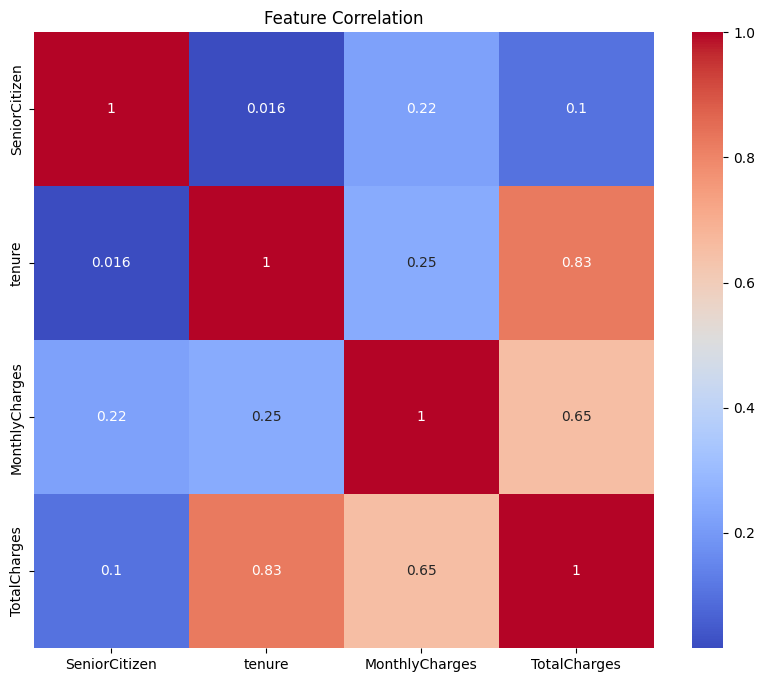

In [42]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

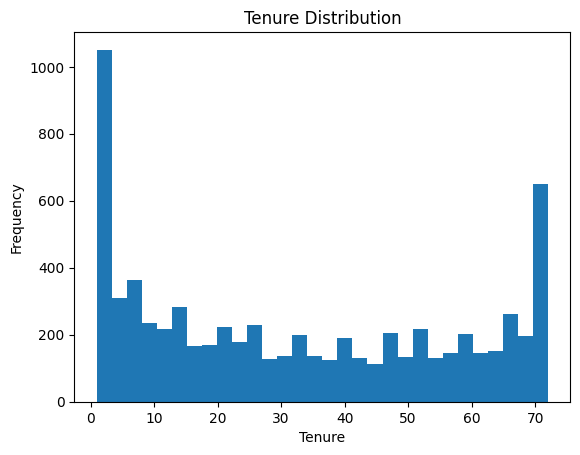

In [43]:
plt.hist(df["tenure"], bins=30)
plt.title("Tenure Distribution")
plt.xlabel("Tenure")
plt.ylabel("Frequency")
plt.show()

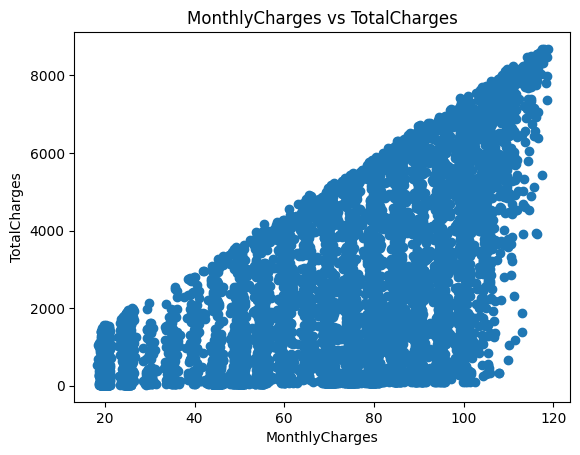

In [44]:
plt.scatter(df["MonthlyCharges"], df["TotalCharges"])
plt.xlabel("MonthlyCharges")
plt.ylabel("TotalCharges")
plt.title("MonthlyCharges vs TotalCharges")
plt.show()

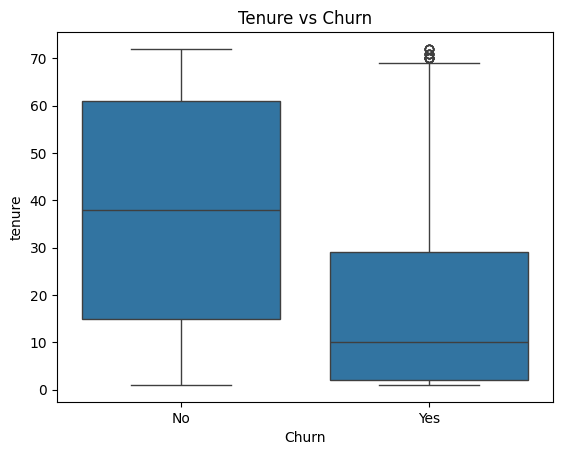

In [45]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

In [46]:
y_pred_rf = rf_model.predict(X_test)

In [47]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.7935153583617748


In [49]:
print("Logistic Regression Confusion Matrix")
print(confusion_matrix(y_test, y_pred_log))

print("Random Forest Confusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

Logistic Regression Confusion Matrix
[[1154  146]
 [ 221  237]]
Random Forest Confusion Matrix
[[1187  113]
 [ 250  208]]


## Conclusion

In this project, machine learning models were used to analyse and predict customer churn in a telecommunications dataset.

The analysis involved:

• Data cleaning and preprocessing  
• Feature scaling and encoding  
• Training logistic regression and random forest models  
• Evaluating model performance using multiple metrics  

The results demonstrate how machine learning can provide valuable insights into customer behaviour and help organisations make data-driven decisions to improve customer retention.